# 05 · Decision Tree, Random Forest & Gradient Boosting

Tree models capture the non-linear patterns from the EDA (the make rate rising then falling with the % of earlier best and the jump size,
and features working together, like a heavy third attempt after a miss) without scaling or bins.

Hyper-parameters are tuned with `GridSearchCV` / `RandomizedSearchCV` and 3-fold `StratifiedKFold` on a **100,000-attempt part of the training sample**,
scored on ROC-AUC (lessons 13–15). The best settings are then refit on the full 300,000-attempt training sample and scored once on the test sample.

In [1]:
import sys, json, time
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from clean import load_attempts
from prep import split, tune_sample, tree_preprocessor, evaluate, save_result, RANDOM_STATE

sns.set_theme(style='whitegrid')
attempts = load_attempts()
X_train, X_test, y_train, y_test = split(attempts)
del attempts
X_tune, y_tune = tune_sample(X_train, y_train)
print('train', X_train.shape, '| tune', X_tune.shape, '| test', X_test.shape)

train (300000, 22) | tune (100000, 22) | test (200000, 22)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import RocCurveDisplay, roc_auc_score

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
best_params, fit_seconds = {}, {}

def refit(model):
    """Fit a tree pipeline on the full training sample and time it."""
    pipe = Pipeline([('prep', tree_preprocessor()), ('model', model)])
    start = time.time()
    pipe.fit(X_train, y_train)
    return pipe, round(time.time() - start)

## 1. Decision Tree (a single, readable tree)

In [3]:
dt_search = GridSearchCV(
    Pipeline([('prep', tree_preprocessor()), ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    {'model__max_depth': [4, 6, 8, 10, 12], 'model__min_samples_leaf': [50, 200, 500]},
    cv=cv, scoring='roc_auc', n_jobs=-1).fit(X_tune, y_tune)
best_params['decision_tree'] = dt_search.best_params_
print(dt_search.best_params_, '| CV ROC-AUC', round(dt_search.best_score_, 4))

dt_params = {k.replace('model__', ''): v for k, v in dt_search.best_params_.items()}
dt, fit_seconds['Decision Tree'] = refit(DecisionTreeClassifier(random_state=RANDOM_STATE, **dt_params))
proba_dt = dt.predict_proba(X_test)[:, 1]
save_result(evaluate('Decision Tree', y_test, proba_dt))

{'model__max_depth': 8, 'model__min_samples_leaf': 500} | CV ROC-AUC 0.7589


,model,threshold,accuracy,balanced_accuracy,precision_made,recall_made,precision_missed,recall_missed,f1_missed,roc_auc
0,Baseline (always made),0.5,0.7807,0.5000,0.7807,1.0000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.5,0.7925,0.5869,0.8132,0.9531,0.5693,0.2208,0.3182,0.7635
2,Decision Tree,0.5,0.7933,0.6119,0.8239,0.9350,0.5553,0.2888,0.3800,0.7650


In [4]:
depth_scores = (pd.DataFrame(dt_search.cv_results_)
                .pivot_table(index='param_model__max_depth', columns='param_model__min_samples_leaf', values='mean_test_score'))
depth_scores.round(4)

param_model__min_samples_leaf,50,200,500
param_model__max_depth,,,
4,0.7437,0.7438,0.7439
6,0.7550,0.7552,0.7559
8,0.7557,0.7580,0.7589
10,0.7500,0.7569,0.7584
12,0.7431,0.7555,0.7584


### The top of the tree

A small tree (depth 3) drawn with `plot_tree` shows the first questions the model asks. Each box shows the split, the share of attempts and the make rate (`value`).

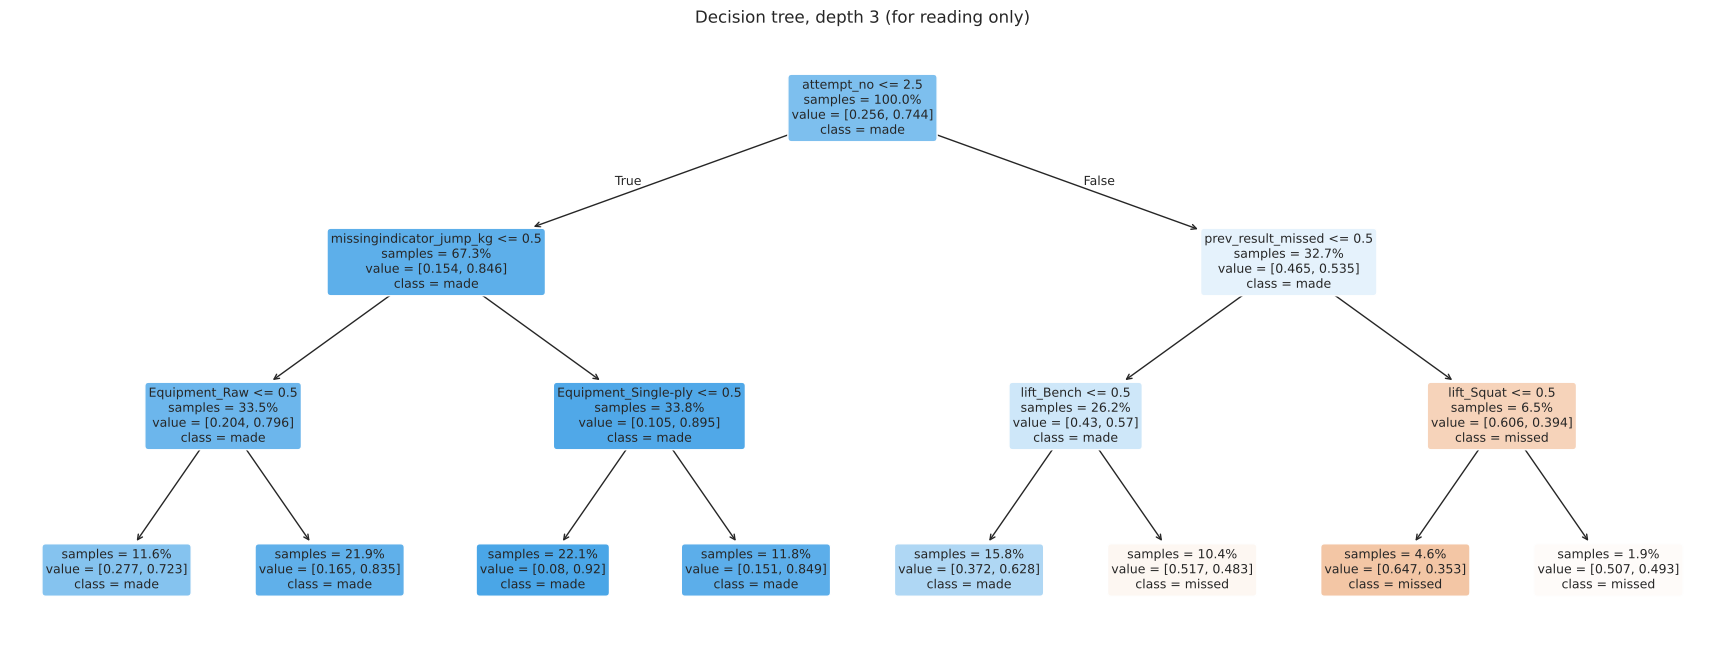

In [5]:
small = Pipeline([('prep', tree_preprocessor()),
                  ('model', DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, random_state=RANDOM_STATE))]).fit(X_train, y_train)
plt.figure(figsize=(22, 8))
plot_tree(small.named_steps['model'], feature_names=small.named_steps['prep'].get_feature_names_out(),
          class_names=['missed', 'made'], filled=True, proportion=True, rounded=True, fontsize=9, impurity=False)
plt.title('Decision tree, depth 3 (for reading only)')
plt.show()

The first question the tree asks is **"is this the third attempt?"**. Third attempts are made only 53.5% of the time, and after a missed second attempt that falls to 39.4% (35.3% on bench and deadlift).
Openers (no jump yet, `missingindicator_jump_kg`) are made 89.5% of the time, with equipped openers lower than raw ones.
These are the same patterns as the EDA, found automatically.

In the full search the best single tree is depth 8 with at least 500 attempts per leaf (CV ROC-AUC 0.759): deeper trees start to overfit unless the leaves are large.

## 2. Random Forest (bagging many trees)

In [6]:
rf_search = RandomizedSearchCV(
    Pipeline([('prep', tree_preprocessor()),
              ('model', RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE))]),
    {'model__max_depth': [None, 12, 20],
     'model__min_samples_leaf': [5, 20, 50, 100],
     'model__max_features': ['sqrt', 0.3, 0.5]},
    n_iter=8, cv=cv, scoring='roc_auc', random_state=RANDOM_STATE).fit(X_tune, y_tune)
best_params['random_forest'] = {**rf_search.best_params_, 'model__n_estimators': 300}
print(rf_search.best_params_, '| CV ROC-AUC', round(rf_search.best_score_, 4))

rf_params = {k.replace('model__', ''): v for k, v in best_params['random_forest'].items()}
rf, fit_seconds['Random Forest'] = refit(RandomForestClassifier(n_jobs=-1, oob_score=True, random_state=RANDOM_STATE, **rf_params))
print('Out-of-bag accuracy:', round(rf.named_steps['model'].oob_score_, 4))
proba_rf = rf.predict_proba(X_test)[:, 1]
save_result(evaluate('Random Forest', y_test, proba_rf))

{'model__min_samples_leaf': 5, 'model__max_features': 0.3, 'model__max_depth': 12} | CV ROC-AUC 0.7696


Out-of-bag accuracy: 0.7734


,model,threshold,accuracy,balanced_accuracy,precision_made,recall_made,precision_missed,recall_missed,f1_missed,roc_auc
0,Baseline (always made),0.5,0.7807,0.5000,0.7807,1.0000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.5,0.7925,0.5869,0.8132,0.9531,0.5693,0.2208,0.3182,0.7635
2,Decision Tree,0.5,0.7933,0.6119,0.8239,0.9350,0.5553,0.2888,0.3800,0.7650
3,Random Forest,0.5,0.7973,0.6119,0.8236,0.9422,0.5779,0.2816,0.3786,0.7747


## 3. Gradient Boosting (trees built one after another, each fixing the last one's errors)

In [7]:
gb_search = RandomizedSearchCV(
    Pipeline([('prep', tree_preprocessor()),
              ('model', GradientBoostingClassifier(random_state=RANDOM_STATE))]),
    {'model__n_estimators': [100, 200, 300],
     'model__learning_rate': [0.05, 0.1],
     'model__max_depth': [3, 4, 5],
     'model__subsample': [0.8, 1.0]},
    n_iter=6, cv=cv, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1).fit(X_tune, y_tune)
best_params['gradient_boosting'] = gb_search.best_params_
print(gb_search.best_params_, '| CV ROC-AUC', round(gb_search.best_score_, 4))

gb_params = {k.replace('model__', ''): v for k, v in gb_search.best_params_.items()}
gb, fit_seconds['Gradient Boosting'] = refit(GradientBoostingClassifier(random_state=RANDOM_STATE, **gb_params))
proba_gb = gb.predict_proba(X_test)[:, 1]
save_result(evaluate('Gradient Boosting', y_test, proba_gb))

{'model__subsample': 0.8, 'model__n_estimators': 300, 'model__max_depth': 5, 'model__learning_rate': 0.05} | CV ROC-AUC 0.7716


,model,threshold,accuracy,balanced_accuracy,precision_made,recall_made,precision_missed,recall_missed,f1_missed,roc_auc
0,Baseline (always made),0.5,0.7807,0.5000,0.7807,1.0000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.5,0.7925,0.5869,0.8132,0.9531,0.5693,0.2208,0.3182,0.7635
2,Decision Tree,0.5,0.7933,0.6119,0.8239,0.9350,0.5553,0.2888,0.3800,0.7650
3,Random Forest,0.5,0.7973,0.6119,0.8236,0.9422,0.5779,0.2816,0.3786,0.7747
4,Gradient Boosting,0.5,0.7977,0.6176,0.8261,0.9385,0.5754,0.2966,0.3914,0.7763


## 4. Overfitting check: train vs test ROC-AUC

In [8]:
fit_check = pd.DataFrame({
    'train_roc_auc': [roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]) for m in [dt, rf, gb]],
    'test_roc_auc': [roc_auc_score(y_test, p) for p in [proba_dt, proba_rf, proba_gb]],
    'fit_seconds': [fit_seconds[n] for n in ['Decision Tree', 'Random Forest', 'Gradient Boosting']],
}, index=['Decision Tree', 'Random Forest', 'Gradient Boosting'])
fit_check['gap'] = fit_check['train_roc_auc'] - fit_check['test_roc_auc']
fit_check.round(4)

,train_roc_auc,test_roc_auc,fit_seconds,gap
Decision Tree,0.7681,0.7650,4,0.0031
Random Forest,0.8085,0.7747,146,0.0338
Gradient Boosting,0.7865,0.7763,552,0.0102


- **Decision Tree:** train 0.768 vs test 0.765, almost no gap (500 attempts per leaf keeps it simple).
- **Random Forest:** the largest gap (0.809 vs 0.775) because its trees are deep (depth 12, leaves of 5), but it still scores better on the test set than the single tree.
- **Gradient Boosting:** a small gap (0.787 vs 0.776) and the best test score; it takes the longest to fit (about 9 minutes on 300,000 attempts).

The test scores of all models are close to their cross-validated scores, so none of them is badly overfit, even though the test set is a different period (2024 onward).

## 5. Comparison so far

In [9]:
results = pd.read_csv('../results/metrics.csv')
results.sort_values('roc_auc', ascending=False)

,model,threshold,accuracy,balanced_accuracy,precision_made,recall_made,precision_missed,recall_missed,f1_missed,roc_auc
4,Gradient Boosting,0.5,0.7977,0.6176,0.8261,0.9385,0.5754,0.2966,0.3914,0.7763
3,Random Forest,0.5,0.7973,0.6119,0.8236,0.9422,0.5779,0.2816,0.3786,0.7747
2,Decision Tree,0.5,0.7933,0.6119,0.8239,0.9350,0.5553,0.2888,0.3800,0.7650
1,Logistic Regression,0.5,0.7925,0.5869,0.8132,0.9531,0.5693,0.2208,0.3182,0.7635
0,Baseline (always made),0.5,0.7807,0.5000,0.7807,1.0000,0.0000,0.0000,0.0000,0.5000


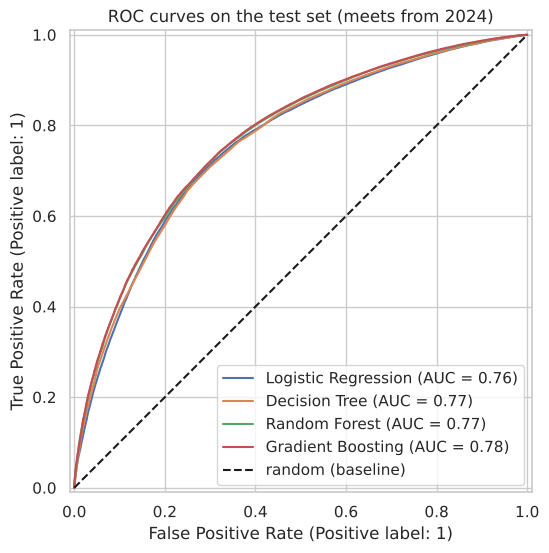

In [10]:
probas = pd.read_csv('../results/test_probas.csv')
fig, ax = plt.subplots(figsize=(7, 6))
for name, p in [('Logistic Regression', probas['logistic_regression']), ('Decision Tree', proba_dt),
                ('Random Forest', proba_rf), ('Gradient Boosting', proba_gb)]:
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='random (baseline)')
ax.set_title('ROC curves on the test set (meets from 2024)'); ax.legend()
plt.show()

- **Gradient Boosting ranks attempts best (ROC-AUC 0.776)**, just ahead of Random Forest (0.775); Decision Tree (0.765) and Logistic Regression (0.764) follow.
- The gain from the ensembles is modest (about 0.01 ROC-AUC over Logistic Regression): most of the signal is in a few strong features (attempt number, previous result, weight vs earlier best) that a linear model with bins also captures.
- At the default 0.5 threshold every model catches fewer than 30% of misses (recall for missed). That is a threshold choice, not a ranking problem, and is tuned in notebook 07.

In [11]:
probas['decision_tree'] = proba_dt.round(5)
probas['random_forest'] = proba_rf.round(5)
probas['gradient_boosting'] = proba_gb.round(5)
probas.to_csv('../results/test_probas.csv', index=False)
with open('../results/best_params.json', 'w') as f:
    json.dump({k: {p: (v if not isinstance(v, np.generic) else v.item()) for p, v in d.items()}
               for k, d in best_params.items()}, f, indent=2)
best_params

{'decision_tree': {'model__max_depth': 8, 'model__min_samples_leaf': 500},
 'random_forest': {'model__min_samples_leaf': 5,
  'model__max_features': 0.3,
  'model__max_depth': 12,
  'model__n_estimators': 300},
 'gradient_boosting': {'model__subsample': 0.8,
  'model__n_estimators': 300,
  'model__max_depth': 5,
  'model__learning_rate': 0.05}}